# Phase 2: Exploratory Data Analysis (EDA)

**Dataset:** `data/distillation_purity_dataset.csv` — 2,000 rows, 9 columns, generated via the
Fenske-Underwood-Gilliland shortcut method (see `docs/assumptions.md` for full methodology).

This notebook investigates 6 questions to validate the dataset before proceeding to ML modeling.

---

## Q1. What do the distributions of each variable look like?
Sampled inputs (z_F, x_B, alpha, F, lam) are roughly uniform, as expected from Latin Hypercube
Sampling. x_D shows a slight upward tilt and alpha a slight taper at the high end — both are
selection effects from the reject-and-resample feasibility filtering, not sampling errors.
Computed outputs (R, N, Q_reb) are right-skewed, consistent with the underlying physics.

## Q2. How does x_D relate to R, N, and z_F individually?
No clean single-variable trend appears in 2D scatter plots. This is expected: x_D was a
sampled design target, not directly caused by any one variable — the true relationship is
multi-variable (R, N, z_F, alpha jointly), which only the ML model will be able to capture.
No broken or impossible values were observed.

## Q3. How does Q_reb relate to R and F?
Clear positive trend with both — consistent with the equation `Q_reb = F(R+1)*lam`. This
confirms the energy layer is behaving physically correctly.

## Q4. Are there strong correlations/multicollinearity between inputs?
Most correlations are weak. Notable exceptions: alpha and N (-0.71) and alpha and R (-0.58),
both physically expected (easier separations need fewer trays and less reflux). R and Q_reb
(0.80) and F and Q_reb (0.50) are strongly positive, confirming the energy relationship. x_D
shows weak correlation with all individual variables, consistent with Q2.

## Q5. Does Q_reb need a log-transform?
Yes. Raw Q_reb is heavily right-skewed; log(Q_reb) is roughly symmetric and bell-shaped.
Q_reb will be log-transformed before ML model training in Phase 3.

## Q6. Are there outliers or suspicious rows?
Sampled input variables show no outliers (expected, since LHS avoids extreme values).
Computed variables (R, N, log(Q_reb)) show some outlier points at the high end, consistent
with their known right-skewed nature from the underlying physics — not data errors.

---

**Conclusion:** the dataset is clean, internally consistent, and reflects the intended
chemical engineering relationships. Ready to proceed to Phase 3 (ML modeling), with the
noted decision to log-transform Q_reb during preprocessing.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/distillation_purity_dataset.csv")
df.head()

,z_F,x_D,x_B,alpha,R,N,system_id,F,lam,Q_reb
0,0.211667,0.937821,0.011657,1.719439,12.738956,18.019330,1,106.472466,34575.793760,5.057818e+07
1,0.666683,0.994606,0.046010,3.348684,1.517252,10.829235,4,334.283969,26188.354696,2.203690e+07
2,0.679236,0.919286,0.045707,2.880570,0.658193,10.524004,3,236.124527,29358.192916,1.149491e+07
3,0.628733,0.994495,0.023351,3.564057,0.959138,14.239327,5,483.069467,25900.771876,2.451249e+07
4,0.457789,0.928645,0.030432,2.963382,1.332820,10.883600,3,353.057729,28931.595360,2.382865e+07


In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   z_F        5000 non-null   float64
 1   x_D        5000 non-null   float64
 2   x_B        5000 non-null   float64
 3   alpha      5000 non-null   float64
 4   R          5000 non-null   float64
 5   N          5000 non-null   float64
 6   system_id  5000 non-null   int64  
 7   F          5000 non-null   float64
 8   lam        5000 non-null   float64
 9   Q_reb      5000 non-null   float64
dtypes: float64(9), int64(1)
memory usage: 390.8 KB


,z_F,x_D,x_B,alpha,R,N,system_id,F,lam,Q_reb
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,0.479337,0.949413,0.030037,2.655164,2.731416,14.190703,2.820400,300.625740,29428.447690,3.397331e+07
std,0.165991,0.027401,0.011550,0.713804,2.223551,5.245690,1.398762,115.775104,2803.785830,2.780475e+07
min,0.200017,0.900014,0.010001,1.500284,0.500417,6.102225,1.000000,100.014153,25005.228714,4.179423e+06
25%,0.336996,0.925772,0.020049,2.040784,1.230936,10.461003,2.000000,200.288025,26999.105155,1.631602e+07
50%,0.474675,0.950661,0.030119,2.611689,2.065921,12.894182,3.000000,301.803885,29161.450731,2.597705e+07
75%,0.615933,0.973242,0.039942,3.253767,3.472210,16.594543,4.000000,400.788797,31774.398367,4.189317e+07
max,0.799887,0.994996,0.049999,3.999377,17.900683,43.700649,5.000000,499.988049,34996.589721,2.607921e+08


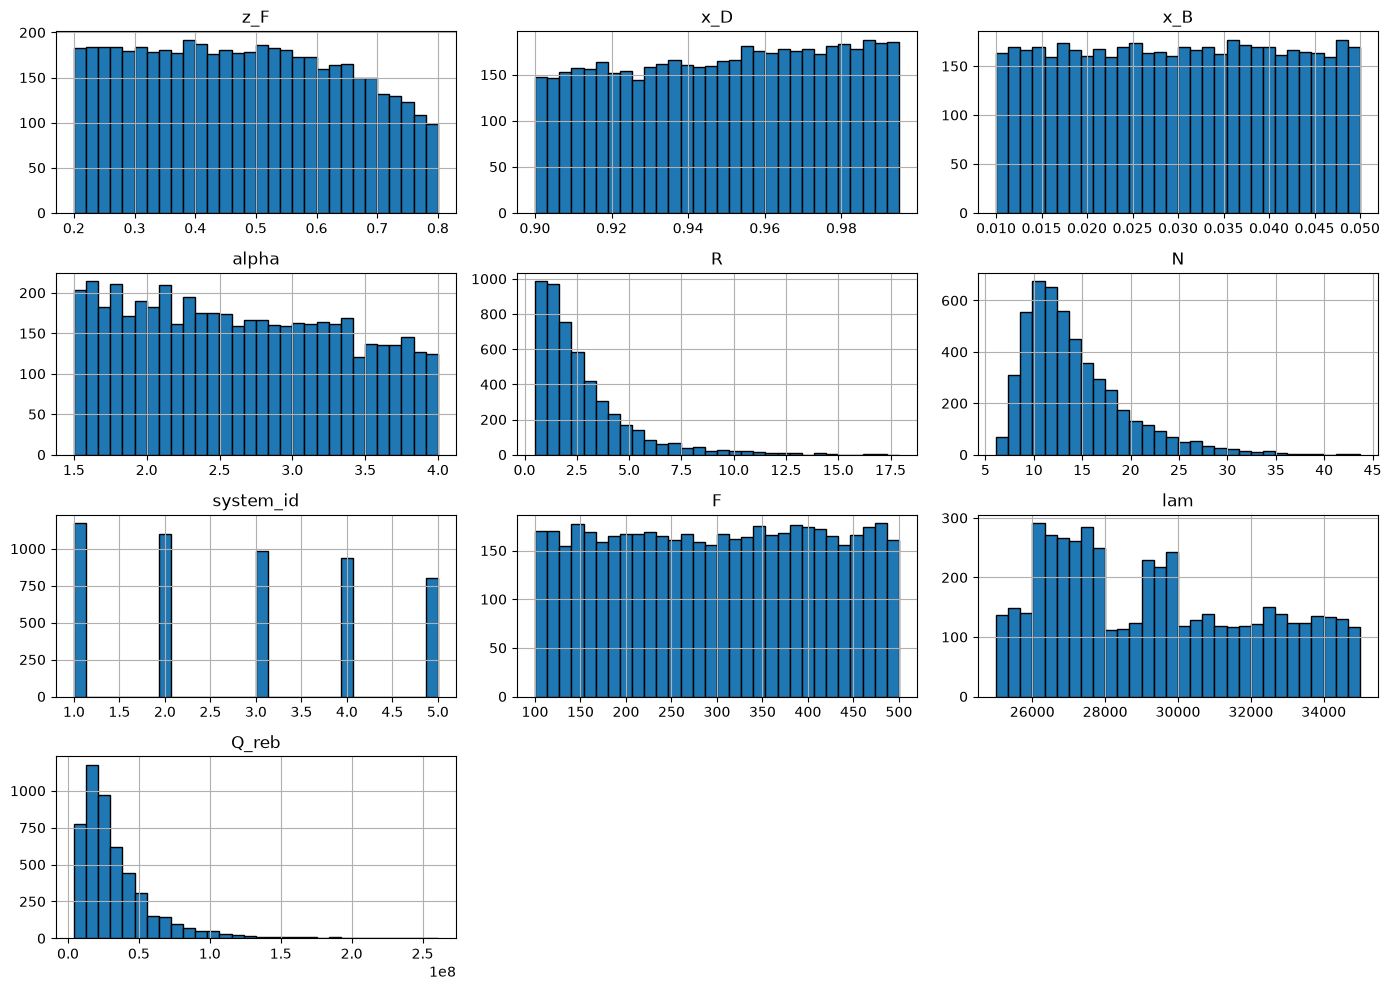

In [3]:
df.hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

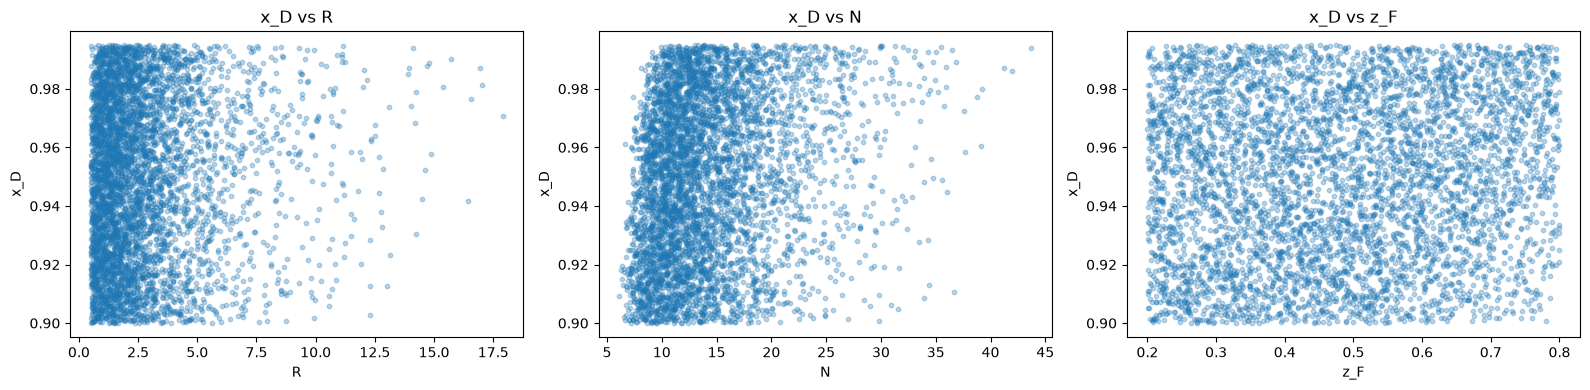

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(df['R'], df['x_D'], alpha=0.3, s=10)
axes[0].set_xlabel('R'); axes[0].set_ylabel('x_D'); axes[0].set_title('x_D vs R')

axes[1].scatter(df['N'], df['x_D'], alpha=0.3, s=10)
axes[1].set_xlabel('N'); axes[1].set_ylabel('x_D'); axes[1].set_title('x_D vs N')

axes[2].scatter(df['z_F'], df['x_D'], alpha=0.3, s=10)
axes[2].set_xlabel('z_F'); axes[2].set_ylabel('x_D'); axes[2].set_title('x_D vs z_F')

plt.tight_layout()
plt.show()

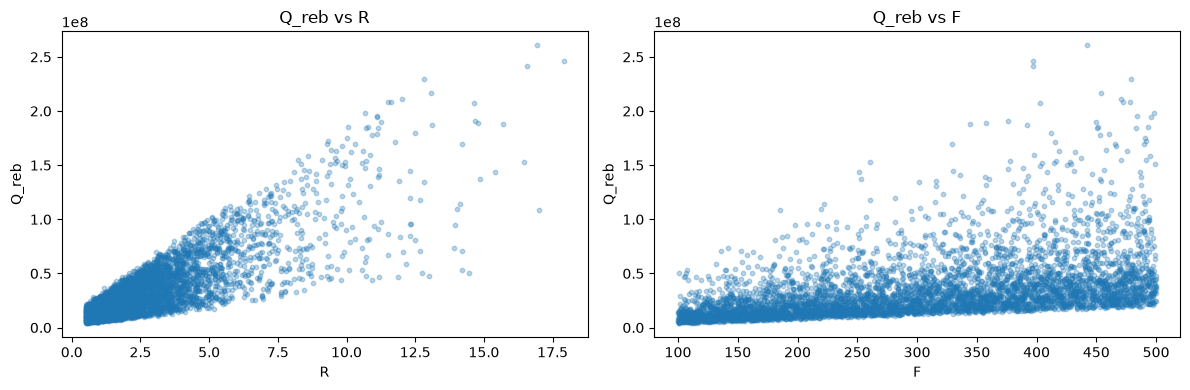

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df['R'], df['Q_reb'], alpha=0.3, s=10)
axes[0].set_xlabel('R'); axes[0].set_ylabel('Q_reb'); axes[0].set_title('Q_reb vs R')

axes[1].scatter(df['F'], df['Q_reb'], alpha=0.3, s=10)
axes[1].set_xlabel('F'); axes[1].set_ylabel('Q_reb'); axes[1].set_title('Q_reb vs F')

plt.tight_layout()
plt.show()

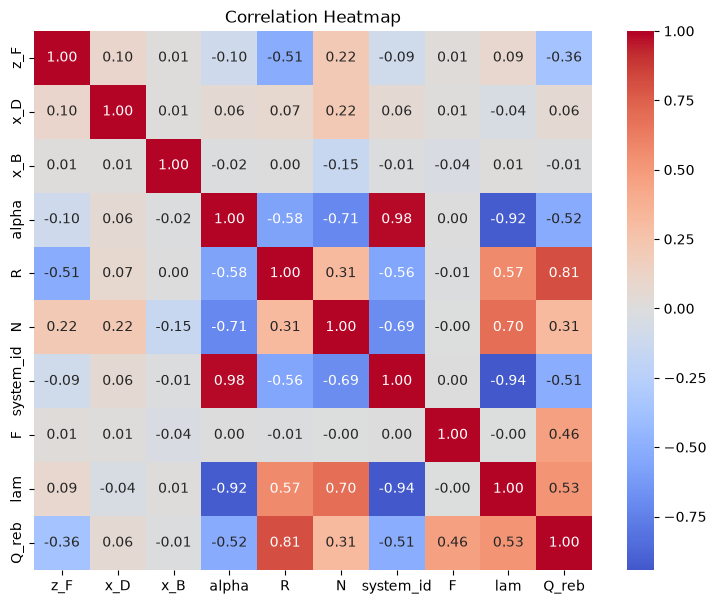

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

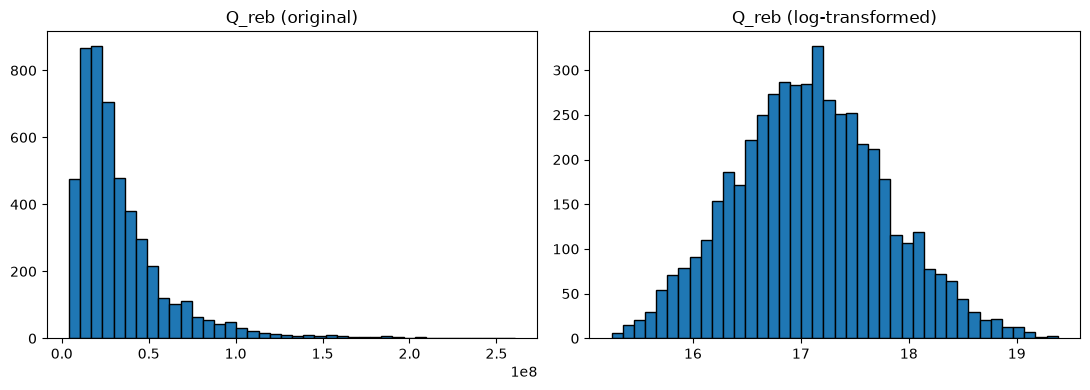

In [7]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df['Q_reb'], bins=40, edgecolor='black')
axes[0].set_title('Q_reb (original)')

axes[1].hist(np.log(df['Q_reb']), bins=40, edgecolor='black')
axes[1].set_title('Q_reb (log-transformed)')

plt.tight_layout()
plt.show()

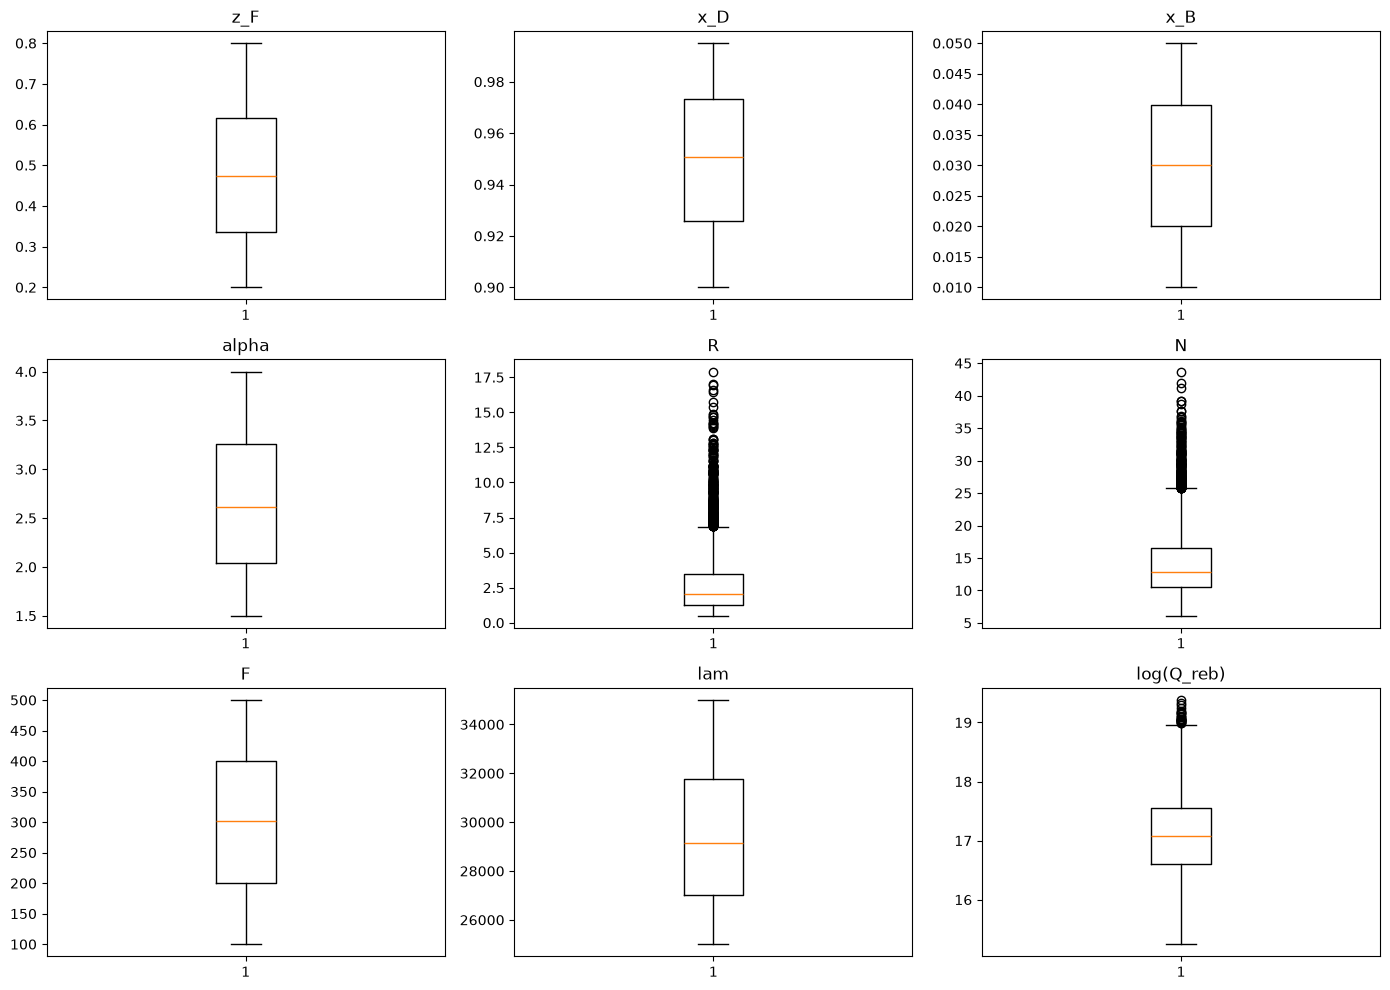

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
cols = ['z_F', 'x_D', 'x_B', 'alpha', 'R', 'N', 'F', 'lam']

for i, col in enumerate(cols):
    ax = axes[i // 3, i % 3]
    ax.boxplot(df[col])
    ax.set_title(col)

axes[2, 2].boxplot(np.log(df['Q_reb']))
axes[2, 2].set_title('log(Q_reb)')

plt.tight_layout()
plt.show()

In [9]:
df = pd.read_csv("../data/distillation_purity_dataset.csv")
print(df[['alpha', 'lam']].corr())

          alpha       lam
alpha  1.000000 -0.922958
lam   -0.922958  1.000000


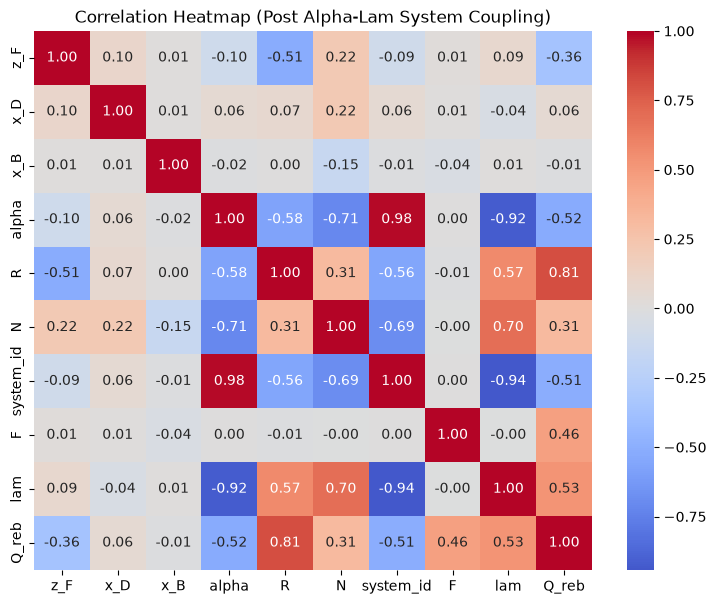

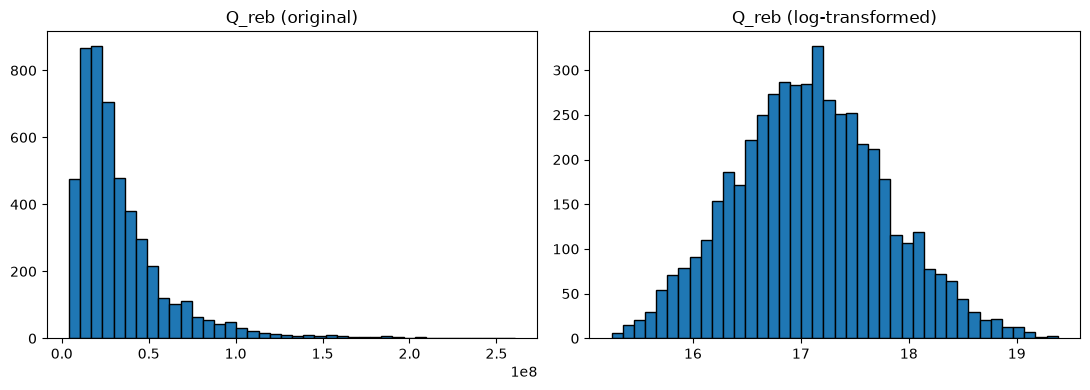

In [10]:
# Re-load the updated dataset (post alpha/lam system coupling)
df = pd.read_csv("../data/distillation_purity_dataset.csv")

# Re-check correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Post Alpha-Lam System Coupling)")
plt.show()

# Re-check Q_reb skew
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df['Q_reb'], bins=40, edgecolor='black')
axes[0].set_title('Q_reb (original)')
axes[1].hist(np.log(df['Q_reb']), bins=40, edgecolor='black')
axes[1].set_title('Q_reb (log-transformed)')
plt.tight_layout()
plt.show()